# Foundations of Generative AI Assignment 3
**Gouri Naik | 230953086**  
English to French translation on OPUS Books. Run in order in a Google Colab GPU runtime. The notebook trains a small Transformer from scratch, adapts mT5-small with LoRA, and uses deterministic prompting for LLaMA 3.2 1B Instruct and Gemma 3 270M IT. Prompting is explicitly permitted for the decoder-only models by the assignment. The same held-out test examples and generation limit are used for the main comparison. Results are computed by this notebook, never prefilled.

**Before running:** create a Hugging Face account, accept the terms on the [LLaMA model page](https://huggingface.co/meta-llama/Llama-3.2-1B-Instruct) and [Gemma model page](https://huggingface.co/google/gemma-3-270m-it), and add a read token to Colab Secrets named `HF_TOKEN`. Never put a token in this notebook or GitHub. Select **Runtime → Change runtime type → T4 GPU**. Free Colab availability varies; checkpoints and result files are saved to Drive if you set `SAVE_TO_DRIVE=True`.

**Dataset:** [Helsinki-NLP/opus_books, en-fr](https://huggingface.co/datasets/Helsinki-NLP/opus_books). License and provenance are described on its dataset card. The subset here is deliberately small for free Colab; numerical results must be interpreted accordingly.

In [1]:
%pip -q install "transformers>=4.53,<5" "datasets>=3,<5" "accelerate>=1,<2" "peft>=0.15,<1" "sentencepiece>=0.2" "sacrebleu>=2.4" "huggingface_hub>=0.30" "pandas>=2" "matplotlib>=3" "python-docx>=1"
%pip -q uninstall -y torchao


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, gc, re, json, time, random, math, unicodedata
from pathlib import Path
import numpy as np, pandas as pd, torch, sentencepiece as spm, sacrebleu
from datasets import load_dataset
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, TaskType
from huggingface_hub import login

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert device.type == 'cuda', 'Select a GPU runtime in Colab before proceeding.'
SAVE_TO_DRIVE = False # change to True if you want the outputs to persist through a Colab reset
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/FGAI_Assignment3_outputs')
else: OUT = Path('/content/FGAI_Assignment3_outputs')
OUT.mkdir(parents=True, exist_ok=True)
print(torch.cuda.get_device_name(0), 'output:', OUT)

Tesla T4 output: /content/FGAI_Assignment3_outputs


## Authentication
Colab Secrets is the recommended method. The account must already have access to both gated repositories. If access is pending, you can run the dataset, Transformer and mT5 sections now; return to this cell later. Do not save an executed notebook containing a token.

In [3]:
from google.colab import userdata
token = userdata.get('HF_TOKEN')
assert token, 'Add a Hugging Face read token to Colab Secrets as HF_TOKEN.'
login(token=token, add_to_git_credential=False)
del token

## Data preparation and fixed split
Normalize Unicode, remove empty/very long pairs, remove duplicate bilingual pairs, then shuffle with a fixed seed before making disjoint train, validation and test partitions. We save test references and split metadata so the comparison can be reproduced.

In [4]:
raw = load_dataset('Helsinki-NLP/opus_books', 'en-fr', split='train')
def clean(s): return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', s)).strip()
pairs = []
seen = set()
for row in raw:
    en, fr = clean(row['translation']['en']), clean(row['translation']['fr'])
    if not (3 <= len(en) <= 180 and 3 <= len(fr) <= 180): continue
    key = (en, fr)
    if key not in seen: seen.add(key); pairs.append(key)
random.Random(SEED).shuffle(pairs)
assert len(pairs) >= 2400, f'Not enough cleaned pairs: {len(pairs)}'
TRAIN_N, VAL_N, TEST_N = 2000, 100, 100
train = pairs[:TRAIN_N]
val = pairs[TRAIN_N:TRAIN_N+VAL_N]
test = pairs[TRAIN_N+VAL_N:TRAIN_N+VAL_N+TEST_N]
assert set(train).isdisjoint(val) and set(train).isdisjoint(test) and set(val).isdisjoint(test)
pd.DataFrame(test, columns=['source_en','reference_fr']).to_csv(OUT/'test_references.csv', index=False)
meta = dict(dataset='Helsinki-NLP/opus_books', config='en-fr', seed=SEED,
            clean_pairs=len(pairs), train=len(train), validation=len(val), test=len(test),
            max_chars=180, normalization='NFKC + collapsed whitespace', gpu=torch.cuda.get_device_name(0))
(OUT/'split_metadata.json').write_text(json.dumps(meta, indent=2))
print(meta); print('Example:', train[0])

README.md: 0.00B [00:00, ?B/s]

en-fr/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

{'dataset': 'Helsinki-NLP/opus_books', 'config': 'en-fr', 'seed': 42, 'clean_pairs': 99264, 'train': 2000, 'validation': 100, 'test': 100, 'max_chars': 180, 'normalization': 'NFKC + collapsed whitespace', 'gpu': 'Tesla T4'}
Example: ('"Do not make yourself uneasy, my dear cousin, about your apparel.', '– Ne vous faites pas de souci, ma chere cousine, au sujet de votre toilette.')


## Basic encoder–decoder Transformer trained from scratch
One shared SentencePiece vocabulary is fitted **only on training pairs**. The model has learned positional embeddings, a three-layer encoder and decoder, teacher forcing during training, and autoregressive greedy decoding during evaluation. This small baseline has no pretrained weights.

In [5]:
corpus = OUT/'spm_train.txt'
with corpus.open('w', encoding='utf-8') as f:
    for en, fr in train: f.write(en+'\n'+fr+'\n')
spm.SentencePieceTrainer.train(input=str(corpus), model_prefix=str(OUT/'translation_spm'),
    vocab_size=4000, model_type='unigram', pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    hard_vocab_limit=False, character_coverage=0.9995)
sp = spm.SentencePieceProcessor(model_file=str(OUT/'translation_spm.model'))
PAD, BOS, EOS = sp.pad_id(), sp.bos_id(), sp.eos_id()
MAX_SRC, MAX_TGT = 64, 64
def sp_encode(s, limit): return [BOS] + sp.encode(s)[:limit-2] + [EOS]
class PairDataset(Dataset):
    def __init__(self, rows): self.rows=rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        en, fr=self.rows[i]
        return torch.tensor(sp_encode(en, MAX_SRC)), torch.tensor(sp_encode(fr, MAX_TGT))
def collate(batch):
    a,b=zip(*batch)
    return (nn.utils.rnn.pad_sequence(a,batch_first=True,padding_value=PAD),
            nn.utils.rnn.pad_sequence(b,batch_first=True,padding_value=PAD))
class BasicTransformer(nn.Module):
    def __init__(self, vocab, d=256, heads=4, layers=3, ff=512):
        super().__init__()
        self.emb=nn.Embedding(vocab,d,padding_idx=PAD)
        self.src_pos=nn.Embedding(MAX_SRC,d); self.tgt_pos=nn.Embedding(MAX_TGT,d)
        self.core=nn.Transformer(d_model=d,nhead=heads,num_encoder_layers=layers,
            num_decoder_layers=layers,dim_feedforward=ff,dropout=0.1,batch_first=True)
        self.out=nn.Linear(d,vocab)
    def forward(self, src, tgt):
        s=self.emb(src)*math.sqrt(self.emb.embedding_dim)+self.src_pos(torch.arange(src.size(1),device=src.device))
        t=self.emb(tgt)*math.sqrt(self.emb.embedding_dim)+self.tgt_pos(torch.arange(tgt.size(1),device=tgt.device))
        mask=nn.Transformer.generate_square_subsequent_mask(tgt.size(1),device=tgt.device)
        return self.out(self.core(s,t,tgt_mask=mask,src_key_padding_mask=src.eq(PAD),
            tgt_key_padding_mask=tgt.eq(PAD),memory_key_padding_mask=src.eq(PAD)))
model=BasicTransformer(sp.vocab_size()).to(device)
basic_params=sum(p.numel() for p in model.parameters())
opt=torch.optim.AdamW(model.parameters(),lr=3e-4)
loss_fn=nn.CrossEntropyLoss(ignore_index=PAD)
loader=DataLoader(PairDataset(train),batch_size=32,shuffle=True,collate_fn=collate)
vloader=DataLoader(PairDataset(val),batch_size=32,collate_fn=collate)
basic_history=[]
t0=time.perf_counter()
for epoch in range(3):
    model.train(); total=0
    for src,tgt in loader:
        src,tgt=src.to(device),tgt.to(device)
        opt.zero_grad(set_to_none=True)
        logits=model(src,tgt[:,:-1]); loss=loss_fn(logits.reshape(-1,sp.vocab_size()),tgt[:,1:].reshape(-1))
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); total+=loss.item()
    model.eval(); vl=0
    with torch.inference_mode():
        for src,tgt in vloader:
            src,tgt=src.to(device),tgt.to(device)
            pred=model(src,tgt[:,:-1]); vl+=loss_fn(pred.reshape(-1,sp.vocab_size()),tgt[:,1:].reshape(-1)).item()
    basic_history.append(dict(epoch=epoch+1,train_loss=total/len(loader),val_loss=vl/len(vloader)))
    print(basic_history[-1])
torch.cuda.synchronize(); basic_train_s=time.perf_counter()-t0
torch.save(model.state_dict(),OUT/'basic_transformer.pt')
pd.DataFrame(basic_history).to_csv(OUT/'basic_training_history.csv',index=False)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


{'epoch': 1, 'train_loss': 6.7107576188587, 'val_loss': 6.233083009719849}
{'epoch': 2, 'train_loss': 5.903554310874333, 'val_loss': 5.938535571098328}
{'epoch': 3, 'train_loss': 5.600143409910656, 'val_loss': 5.748039722442627}


In [6]:
def basic_translate(en):
    src=torch.tensor([sp_encode(en,MAX_SRC)],device=device)
    tgt=torch.tensor([[BOS]],device=device)
    with torch.inference_mode():
        for _ in range(MAX_TGT-1):
            nxt=model(src,tgt)[:,-1].argmax(-1,keepdim=True)
            tgt=torch.cat([tgt,nxt],dim=1)
            if nxt.item()==EOS: break
    return sp.decode([i for i in tgt[0,1:].tolist() if i not in (PAD,EOS)])
basic_test=[]
t0=time.perf_counter()
for en,_ in test: basic_test.append(basic_translate(en))
torch.cuda.synchronize(); basic_infer_s=time.perf_counter()-t0
print('Basic example:',basic_test[0])
del model,opt,loader,vloader
gc.collect(); torch.cuda.empty_cache()

Basic example: Il, et le la l'était la l'était la l'était é, et, et, et, et, et, et de la l'était la l'était la l'était la l'était la l'était la l'était la l'était la l'était


## mT5 small with LoRA fine-tuning
Only low-rank adapter matrices are trained. Fine-tuning time excludes the first download, dataset preprocessing and test inference. Full and trainable parameter counts are recorded.

In [7]:
mt5_id='google/mt5-small'
mtok=AutoTokenizer.from_pretrained(mt5_id)
base=AutoModelForSeq2SeqLM.from_pretrained(mt5_id)
mt5_params=sum(p.numel() for p in base.parameters())
cfg=LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM,r=8,lora_alpha=16,lora_dropout=0.05,target_modules=['q','v'])
mt5=get_peft_model(base,cfg).to(device)
mt5_trainable=sum(p.numel() for p in mt5.parameters() if p.requires_grad)
def mt5_batch(rows):
    inputs=mtok(['translate English to French: '+x[0] for x in rows],return_tensors='pt',
                padding=True,truncation=True,max_length=96)
    labels=mtok(text_target=[x[1] for x in rows],return_tensors='pt',
                padding=True,truncation=True,max_length=96).input_ids
    labels[labels==mtok.pad_token_id]=-100
    return {**{k:v.to(device) for k,v in inputs.items()},'labels':labels.to(device)}
mt5_opt=torch.optim.AdamW((p for p in mt5.parameters() if p.requires_grad),lr=3e-4)
mt5_history=[]
t0=time.perf_counter()
for epoch in range(1):
    mt5.train(); losses=[]
    indices=list(range(len(train))); random.Random(SEED+epoch).shuffle(indices)
    for i in range(0,len(indices),8):
        batch=mt5_batch([train[j] for j in indices[i:i+8]])
        mt5_opt.zero_grad(set_to_none=True)
        loss=mt5(**batch).loss; loss.backward()
        nn.utils.clip_grad_norm_((p for p in mt5.parameters() if p.requires_grad),1.0)
        mt5_opt.step(); losses.append(loss.item())
    mt5.eval(); vloss=[]
    with torch.inference_mode():
        for i in range(0,len(val),8): vloss.append(mt5(**mt5_batch(val[i:i+8])).loss.item())
    mt5_history.append(dict(epoch=epoch+1,train_loss=float(np.mean(losses)),val_loss=float(np.mean(vloss))))
    print(mt5_history[-1])
torch.cuda.synchronize(); mt5_train_s=time.perf_counter()-t0
mt5.save_pretrained(OUT/'mt5_lora_adapter'); mtok.save_pretrained(OUT/'mt5_tokenizer')
pd.DataFrame(mt5_history).to_csv(OUT/'mt5_training_history.csv',index=False)

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

{'epoch': 1, 'train_loss': 14.131390636444092, 'val_loss': 5.758921073033259}


In [8]:
def mt5_translate(en):
    batch=mtok('translate English to French: '+en,return_tensors='pt',truncation=True,max_length=96).to(device)
    with torch.inference_mode(): ids=mt5.generate(**batch,max_new_tokens=64,do_sample=False,num_beams=1)
    return mtok.decode(ids[0],skip_special_tokens=True).strip()
mt5_test=[]; t0=time.perf_counter()
for en,_ in test: mt5_test.append(mt5_translate(en))
torch.cuda.synchronize(); mt5_infer_s=time.perf_counter()-t0
print('mT5 example:',mt5_test[0])
del mt5,base,mt5_opt,mtok
gc.collect(); torch.cuda.empty_cache()

mT5 example: <extra_id_0> a s a s a s a s a s a s a s a . à l' a ' à l' a . à l . à l .


## LLaMA and Gemma prompting
These instruction-tuned decoder-only models are **not fine-tuned**. They use the same zero-shot instruction, test set, 64 generated-token cap and greedy decoding. Different chat templates and tokenizers are intrinsic model differences. Prompt inference time includes tokenization and generation but excludes model download/loading. The LLaMA model may need its access request approved; Gemma requires accepting its license. Runs are sequential to fit free Colab memory.

In [9]:
prompt='Translate the following English sentence into French. Output only the French translation.\nEnglish: {source}'
def decoder_run(model_id, label):
    tokenizer=AutoTokenizer.from_pretrained(model_id)
    dtype=torch.float32 if label=='Gemma' else torch.float16
    extra={'attn_implementation':'eager'} if label=='Gemma' else {}
    net=AutoModelForCausalLM.from_pretrained(model_id,torch_dtype=dtype,low_cpu_mem_usage=True,**extra).to(device)
    net.eval()
    count=sum(p.numel() for p in net.parameters())
    def translate(en, temperature=None):
        messages=[{'role':'user','content':prompt.format(source=en)}]
        inputs=tokenizer.apply_chat_template(messages,tokenize=True,add_generation_prompt=True,return_dict=True,return_tensors='pt').to(device)
        args=dict(max_new_tokens=64,pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id)
        if temperature is None: args.update(do_sample=False,num_beams=1)
        else: args.update(do_sample=True,temperature=temperature,top_p=0.9)
        with torch.inference_mode(): generated=net.generate(**inputs,**args)[0,inputs['input_ids'].shape[-1]:]
        return tokenizer.decode(generated,skip_special_tokens=True).strip().split('\n')[0].strip()
    outputs=[]; start=time.perf_counter()
    for en,_ in test: outputs.append(translate(en))
    torch.cuda.synchronize(); elapsed=time.perf_counter()-start
    # The temperature comparison is separate from the deterministic main evaluation.
    temp_rows=[]
    if label=='LLaMA':
        for temp in (0.3,0.7,1.0):
            for en,fr in test[:5]:
                temp_rows.append(dict(model=label,temperature=temp,source_en=en,reference_fr=fr,
                                      translation_fr=translate(en,temperature=temp)))
    del net,tokenizer
    gc.collect(); torch.cuda.empty_cache()
    return outputs,elapsed,count,temp_rows

llama_id='meta-llama/Llama-3.2-1B-Instruct'
llama_test,llama_infer_s,llama_params,llama_temp=decoder_run(llama_id,'LLaMA')
print('LLaMA example:',llama_test[0])

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LLaMA example: Now, un dimanche, le modèle n'est pas revenu; il n'y a pas de doute qu'elle avait trouvé un endroit plus chaud et plus confortable.


In [10]:
gemma_id='google/gemma-3-270m-it'
gemma_test,gemma_infer_s,gemma_params,gemma_temp=decoder_run(gemma_id,'Gemma')
print('Gemma example:',gemma_test[0])
pd.DataFrame(llama_temp).to_csv(OUT/'temperature_samples.csv',index=False)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/536M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Gemma example: La modèle n'a pas retourné dimanche, et elle avait trouvé une place plus confortable et plus chaleureuse.


## Same-test-set evaluation and comparisons
SacreBLEU corpus BLEU and corpus chrF use a single reference per source. Greedy decoding provides a reproducible main comparison. Prompt-only models have no task-specific training time; this is marked `N/A`, not zero. Model download/loading and training durations are excluded from inference time. Resource limits, model size, tokenization, pretraining and adaptation method all affect scores, so architecture alone cannot explain the differences.

,model,bleu,chrf,training_seconds,inference_total_seconds,inference_seconds_per_sentence,parameters,trainable_parameters
0,Basic Transformer,0.213,7.613,14.627,29.836,0.298,6039456,6039456
1,mT5-small LoRA,0.124,4.092,41.201,114.947,1.149,300176768,344064
2,LLaMA 3.2 1B prompt,12.138,33.671,NaN,55.096,0.551,1235814400,0
3,Gemma 3 270M prompt,7.677,29.977,NaN,79.594,0.796,268098176,0


,source_en,reference_fr,basic_transformer,mt5,llama,gemma
0,"Now, one Sunday the model did not return; no d...","Sur ces entrefaites, le modèle le quitta brusq...","Il, et le la l'était la l'était la l'était é, ...",<extra_id_0> a s a s a s a s a s a s a s a . à...,"Now, un dimanche, le modèle n'est pas revenu; ...","La modèle n'a pas retourné dimanche, et elle a..."
1,The history of England serves as a mirror to s...,L’histoire d’Angleterre me sert de miroir pour...,Il ne é de l’était de l’était de l’était de l’...,<extra_id_0> a ' ' ' ' ' ' . . . . . . . .. .....,English: La histoire d'Angleterre sert de miro...,Lahistoire de l'Angleterre est un reflet à la ...
2,"""The 'Maria Stella!'","La Maria-Stella! un beau baleinier, ma foi!","-- -- -- -- -- Je ne, dit-il, dit-il, dit-il, ...",<extra_id_0>' <extra_id_1>' 'Maria '.' 'Maria ...,The French translation of the given English se...,"La ""Maria Stella!"""
3,"""To-morrow morning at six precisely,"" my uncle...","«À demain matin, dit mon oncle, nous partons à...","-- -- -- -- -- -- -- -- -- -- -- -- Je, je, je...",<extra_id_0> à à s à s à s à s à s à s à s à s...,"""À l'aube de demain, à six heures précis, mon ...","""À demain matin précisément, mon grand-père a ..."
4,"Yes, do that, for my sake, to oblige me.","Oui fais cela! pour moi, pour m’obliger.","Il, il, il, il, il, et, il, il, il, il, et, il...","<extra_id_0>, à faire, à faire, à faire, à fai...","Oui, faites-le, pour mon compte, pour me faire.","Yes, do that, for my sake, to oblige me."
5,"""Yes, I am stifling; let us go.""","-- Oui, j’étouffe; partons.","-- -- -- -- Je ne, je, je, je, je, je ne vous,...","<extra_id_0>, à s' s' s à s à s à s à s à s à ...","""Oui, je suis en colère; allons-y.""","Yes, I am stifling; let us go."
6,"The journey had been long, and the task of get...","L'étape avait été longue, et l'incident du bal...","Ils de la l'étaits, et de la la la la l'étaits...",<extra_id_0> à la à la à la à la à l à l à l à...,The translation of the given sentence into Fre...,"Le voyage avait été long, et la tâche de se re..."
7,"""But don't you conclude--?""",--Mais n'en concluez-vous pas?...,-- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -...,<extra_id_0>' <extra_id_1>' '' ' '.' ' ' '. '....,"""Mais ne concluez pas?""",But don't you conclude--
8,"""No, no, Jim,"" cried the smith, abruptly.","-- Non, non, Jim, dit le forgeron intervenant ...","-- -- -- -- -- Je, dit, je, je, je, je, je, je...","<extra_id_0>, à ', ' ', ' ', ' ', ' ', ' ', ' ...","""Non, non, Jim,"" criait le foudre, abruptement.","No, no, Jim"
9,I felt I was done for.,Je me sentis perdu.,Je ne me je ne me.,<extra_id_0>. <extra_id_1>. .. .. .. ... ........,Ile.,Je me suis senti terminé.


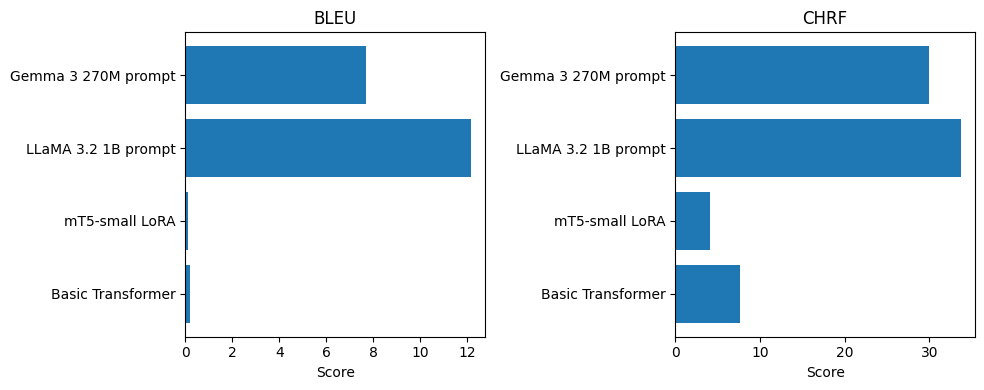

In [11]:
refs=[fr for _,fr in test]
predictions={'Basic Transformer':basic_test,'mT5-small LoRA':mt5_test,
             'LLaMA 3.2 1B prompt':llama_test,'Gemma 3 270M prompt':gemma_test}
assert all(len(p)==len(refs) for p in predictions.values())
times={'Basic Transformer':(basic_train_s,basic_infer_s,basic_params,basic_params),
       'mT5-small LoRA':(mt5_train_s,mt5_infer_s,mt5_params,mt5_trainable),
       'LLaMA 3.2 1B prompt':(None,llama_infer_s,llama_params,0),
       'Gemma 3 270M prompt':(None,gemma_infer_s,gemma_params,0)}
records=[]
for name,preds in predictions.items():
    train_s,infer_s,params,trainable=times[name]
    records.append(dict(model=name,bleu=sacrebleu.corpus_bleu(preds,[refs]).score,
        chrf=sacrebleu.corpus_chrf(preds,[refs]).score,training_seconds=train_s,
        inference_total_seconds=infer_s,inference_seconds_per_sentence=infer_s/len(test),
        parameters=params,trainable_parameters=trainable))
results=pd.DataFrame(records)
samples=pd.DataFrame({'source_en':[en for en,_ in test], 'reference_fr':refs,
    'basic_transformer':basic_test,'mt5':mt5_test,'llama':llama_test,'gemma':gemma_test})
results.to_csv(OUT/'results.csv',index=False); samples.to_csv(OUT/'translations.csv',index=False)
display(results.round(3)); display(samples.head(10))
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,col in zip(axes,['bleu','chrf']):
    ax.barh(results.model,results[col]); ax.set_title(col.upper()); ax.set_xlabel('Score')
fig.tight_layout(); fig.savefig(OUT/'metric_comparison.png',dpi=180,bbox_inches='tight'); plt.show()

## Gemma temperature check after core results
The main four-model comparison has already been saved. For a small exploratory check, set `RUN_GEMMA_TEMPERATURE=True` and run the next cell. This loads the 270M model in float32 separately. If an error occurs here, the main `results.csv` and `translations.csv` remain available.


In [12]:
RUN_GEMMA_TEMPERATURE = False  # Set to True after confirming results.csv exists
if RUN_GEMMA_TEMPERATURE:
    tok=AutoTokenizer.from_pretrained(gemma_id)
    net=AutoModelForCausalLM.from_pretrained(gemma_id,torch_dtype=torch.float32,attn_implementation='eager').to(device)
    net.eval()
    for temperature in (0.3,0.7,1.0):
        for en,fr in test[:5]:
            inputs=tok.apply_chat_template([{'role':'user','content':prompt.format(source=en)}],
                tokenize=True,add_generation_prompt=True,return_dict=True,return_tensors='pt').to(device)
            with torch.inference_mode():
                ids=net.generate(**inputs,max_new_tokens=64,do_sample=True,
                    temperature=temperature,top_p=0.9,
                    pad_token_id=tok.pad_token_id or tok.eos_token_id)[0,inputs['input_ids'].shape[-1]:]
            gemma_temp.append(dict(model='Gemma',temperature=temperature,source_en=en,
                reference_fr=fr,translation_fr=tok.decode(ids,skip_special_tokens=True).strip().split('\n')[0].strip()))
    pd.DataFrame(llama_temp+gemma_temp).to_csv(OUT/'temperature_samples.csv',index=False)
    print('Saved temperature samples:',OUT/'temperature_samples.csv')
    del net,tok
    gc.collect();torch.cuda.empty_cache()
else:
    print('Core results saved. Set RUN_GEMMA_TEMPERATURE=True later for Gemma sampling.')


Core results saved. Set RUN_GEMMA_TEMPERATURE=True later for Gemma sampling.


## Qualitative and responsible AI review
Inspect `translations.csv` and `temperature_samples.csv` before completing the review below. Mark omissions, additions, named entities, gendered terms, culturally specific wording, and sensitive content. The five temperature examples are an exploratory analysis, not a controlled quality estimate. Do not claim a model is fair or safe from BLEU/chrF alone. OPUS Books is literary text and this English–French subset cannot establish performance on other domains or languages.

Suggested safeguards: human review for medical/legal/safety-sensitive uses; preserve source and confidence context; check names, numbers and negation; test varied identities and dialects; allow user correction; document dataset provenance and limits; audit harmful outputs; avoid publishing private text to an unapproved service.

In [13]:
# Fill these observations after reviewing the actual translations; leave unknowns explicit.
review = {
  'observed_examples': [], # e.g. {'row': 4, 'model': 'Gemma', 'observation': '...'}
  'bias_or_cultural_issues': 'Review output and enter evidence here.',
  'hallucinations_or_omissions': 'Review output and enter evidence here.',
  'sensitive_content': 'Review output and enter evidence here.',
  'temperature_analysis': 'Compare temperature_samples.csv and enter observations here.',
  'limitations': 'Small literary subset, single seed, unequal pretrained model size and training.'
}
(OUT/'qualitative_review.json').write_text(json.dumps(review,indent=2,ensure_ascii=False))
print('Write evidence-based notes in',OUT/'qualitative_review.json')

Write evidence-based notes in /content/FGAI_Assignment3_outputs/qualitative_review.json


In [14]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

folder = Path("/content/FGAI_Assignment3_outputs")
names = [
    "results.csv", "translations.csv", "temperature_samples.csv",
    "split_metadata.json", "basic_training_history.csv",
    "mt5_training_history.csv", "metric_comparison.png"
]
with ZipFile("/content/FGAI_Assignment3_results.zip", "w", ZIP_DEFLATED) as z:
    for name in names:
        if (folder / name).exists():
            z.write(folder / name, name)

files.download("/content/FGAI_Assignment3_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from pathlib import Path
folder = Path("/content/FGAI_Assignment3_outputs")
print("Results folder exists:", folder.exists())
if folder.exists():
    print([p.name for p in folder.iterdir()])

Results folder exists: True
['translation_spm.model', 'split_metadata.json', 'basic_training_history.csv', 'temperature_samples.csv', 'translation_spm.vocab', 'qualitative_review.json', 'mt5_training_history.csv', 'test_references.csv', 'mt5_tokenizer', 'results.csv', 'metric_comparison.png', 'translations.csv', 'mt5_lora_adapter', 'spm_train.txt', 'basic_transformer.pt']
